In [1]:
import os
import copy
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    roc_auc_score
)
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Libraries imported successfully.")
print("Device:", DEVICE)


Libraries imported successfully.
Device: cpu


In [2]:

DATA_PATH = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully.
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:

print("Dataset Information")
print("-" * 50)

df.info()

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nStatistical summary:")
display(df.describe(include="all").T)


Dataset Information
--------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-nu

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

customer_ids = df["customerID"].copy()

df = df.drop(columns=["customerID"])

df["Churn"] = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

print("Missing values before preprocessing:")
display(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
display(df["Churn"].value_counts())


Missing values before preprocessing:


TotalCharges    11
dtype: int64


Duplicate rows: 22

Target distribution:


Churn
0    5174
1    1869
Name: count, dtype: int64

,Customer Count,Percentage
No Churn,5174,73.463013
Churn,1869,26.536987


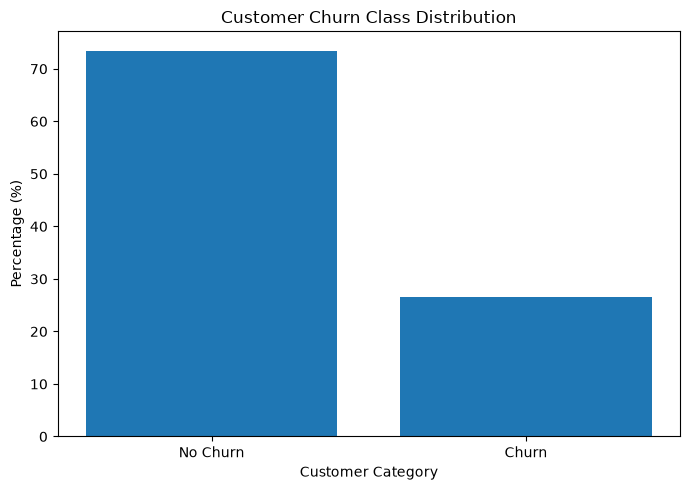

Customers who churned: 26.54%
Customers who stayed: 73.46%


In [5]:

class_counts = df["Churn"].value_counts().sort_index()

class_percentages = (
    df["Churn"].value_counts(normalize=True).sort_index() * 100
)

class_balance = pd.DataFrame({
    "Customer Count": class_counts,
    "Percentage": class_percentages
})

class_balance.index = ["No Churn", "Churn"]

display(class_balance)

plt.figure(figsize=(7, 5))

plt.bar(
    ["No Churn", "Churn"],
    class_percentages.values
)

plt.title("Customer Churn Class Distribution")
plt.xlabel("Customer Category")
plt.ylabel("Percentage (%)")
plt.tight_layout()
plt.show()

print(f"Customers who churned: {class_percentages[1]:.2f}%")
print(f"Customers who stayed: {class_percentages[0]:.2f}%")


In [6]:

X = df.drop(columns=["Churn"])
y = df["Churn"]

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nCategorical features:", categorical_features)

print("\nTotal input features:", X.shape[1])


Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Total input features: 19


In [7]:

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=SEED,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Testing"],
    "Samples": [
        len(X_train),
        len(X_val),
        len(X_test)
    ],
    "Percentage": [
        len(X_train) / len(X) * 100,
        len(X_val) / len(X) * 100,
        len(X_test) / len(X) * 100
    ],
    "Churn Percentage": [
        y_train.mean() * 100,
        y_val.mean() * 100,
        y_test.mean() * 100
    ]
})

display(split_summary.round(2))


Training set: (4225, 19)
Validation set: (1409, 19)
Testing set: (1409, 19)


,Dataset,Samples,Percentage,Churn Percentage
0,Training,4225,59.99,26.53
1,Validation,1409,20.01,26.54
2,Testing,1409,20.01,26.54


In [8]:

numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Convert to dense arrays for PyTorch
X_train_processed = np.asarray(
    X_train_processed, dtype=np.float32
)

X_val_processed = np.asarray(
    X_val_processed, dtype=np.float32
)

X_test_processed = np.asarray(
    X_test_processed, dtype=np.float32
)

y_train_np = y_train.to_numpy(dtype=np.float32)
y_val_np = y_val.to_numpy(dtype=np.float32)
y_test_np = y_test.to_numpy(dtype=np.float32)

print("Preprocessing completed.")

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)
print("Testing shape:", X_test_processed.shape)

print("Number of input features:", X_train_processed.shape[1])


Preprocessing completed.
Training shape: (4225, 45)
Validation shape: (1409, 45)
Testing shape: (1409, 45)
Number of input features: 45


In [9]:

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=SEED
)

logistic_model.fit(X_train_processed, y_train_np)

logistic_val_predictions = logistic_model.predict(
    X_val_processed
)

print("Logistic Regression Validation Results")
print(
    classification_report(
        y_val_np,
        logistic_val_predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)


Logistic Regression Validation Results
              precision    recall  f1-score   support

    No Churn       0.86      0.91      0.88      1035
       Churn       0.70      0.59      0.64       374

    accuracy                           0.82      1409
   macro avg       0.78      0.75      0.76      1409
weighted avg       0.82      0.82      0.82      1409



In [10]:

random_forest_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    random_state=SEED,
    n_jobs=-1
)

random_forest_model.fit(
    X_train_processed,
    y_train_np.astype(int)
)

rf_val_predictions = random_forest_model.predict(
    X_val_processed
)

print("Random Forest Validation Results")

print(
    classification_report(
        y_val_np,
        rf_val_predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)


Random Forest Validation Results
              precision    recall  f1-score   support

    No Churn       0.83      0.91      0.87      1035
       Churn       0.66      0.48      0.56       374

    accuracy                           0.80      1409
   macro avg       0.74      0.70      0.71      1409
weighted avg       0.78      0.80      0.79      1409



In [11]:

def calculate_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, zero_division=0
        )
    }

baseline_results = pd.DataFrame({
    "Logistic Regression": calculate_metrics(
        y_val_np, logistic_val_predictions
    ),
    "Random Forest": calculate_metrics(
        y_val_np, rf_val_predictions
    )
}).T

display(baseline_results.round(4))


,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.8240,0.6981,0.5936,0.6416
Random Forest,0.7963,0.6593,0.4813,0.5564


In [12]:

X_train_tensor = torch.tensor(
    X_train_processed,
    dtype=torch.float32
)

X_val_tensor = torch.tensor(
    X_val_processed,
    dtype=torch.float32
)

X_test_tensor = torch.tensor(
    X_test_processed,
    dtype=torch.float32
)

y_train_tensor = torch.tensor(
    y_train_np.reshape(-1, 1),
    dtype=torch.float32
)

y_val_tensor = torch.tensor(
    y_val_np.reshape(-1, 1),
    dtype=torch.float32
)

y_test_tensor = torch.tensor(
    y_test_np.reshape(-1, 1),
    dtype=torch.float32
)

BATCH_SIZE = 64

train_dataset = TensorDataset(
    X_train_tensor,
    y_train_tensor
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

print("PyTorch tensors created successfully.")
print("Input dimension:", X_train_tensor.shape[1])


PyTorch tensors created successfully.
Input dimension: 45


In [ ]:

class ChurnMLP(nn.Module):

    def __init__(self, input_size, dropout_rate=0.0):

        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Dropout(dropout_rate),

            nn.Linear(64, 32),
            nn.ReLU(),                                                                                                                                 
            nn.Dropout(dropout_rate),

            nn.Linear(32, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)

input_size = X_train_processed.shape[1]

model = ChurnMLP(
    input_size=input_size,
    dropout_rate=0.0
).to(DEVICE)

print(model)


ChurnMLP(
  (network): Sequential(
    (0): Linear(in_features=45, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.0, inplace=False)
    (3): Linear(in_features=64, out_features=32, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.0, inplace=False)
    (6): Linear(in_features=32, out_features=1, bias=True)
    (7): Sigmoid()
  )
)


In [14]:

def train_model(
    dropout_rate=0.0,
    l2_value=0.0,
    epochs=50,
    patience=5
):

    model = ChurnMLP(
        input_size=input_size,
        dropout_rate=dropout_rate
    ).to(DEVICE)

    criterion = nn.BCELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=l2_value
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_weights = None
    patience_counter = 0
    best_epoch = 0

    X_val_device = X_val_tensor.to(DEVICE)
    y_val_device = y_val_tensor.to(DEVICE)

    for epoch in range(epochs):

        model.train()
        train_loss_total = 0.0

        for batch_X, batch_y in train_loader:

            batch_X = batch_X.to(DEVICE)
            batch_y = batch_y.to(DEVICE)

            optimizer.zero_grad()

            predictions = model(batch_X)

            loss = criterion(predictions, batch_y)

            loss.backward()
            optimizer.step()

            train_loss_total += loss.item() * len(batch_X)

        train_loss = (
            train_loss_total / len(train_dataset)
        )

        model.eval()

        with torch.no_grad():

            val_predictions = model(X_val_device)

            val_loss = criterion(
                val_predictions,
                y_val_device
            ).item()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_weights = copy.deepcopy(
                model.state_dict()
            )

            best_epoch = epoch + 1
            patience_counter = 0

        else:

            patience_counter += 1

        if patience_counter >= patience:
            break

    model.load_state_dict(best_weights)

    return model, history, best_epoch, best_val_loss


print("Training function defined successfully.")


Training function defined successfully.


In [15]:

initial_model, initial_history, initial_best_epoch, initial_best_loss = train_model(
    dropout_rate=0.0,
    l2_value=0.0,
    epochs=50,
    patience=5
)

print("Initial Neural Network Training Completed")
print("Best Epoch:", initial_best_epoch)
print("Best Validation Loss:", round(initial_best_loss, 4))


Initial Neural Network Training Completed
Best Epoch: 9
Best Validation Loss: 0.4028


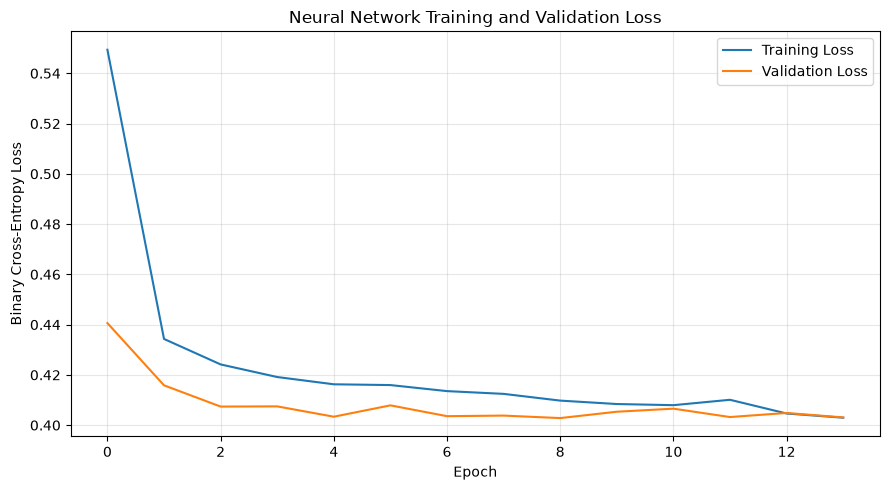

In [16]:

plt.figure(figsize=(9, 5))

plt.plot(
    initial_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    initial_history["val_loss"],
    label="Validation Loss"
)

plt.title("Neural Network Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [17]:

initial_model.eval()

with torch.no_grad():

    initial_val_probabilities = initial_model(
        X_val_tensor.to(DEVICE)
    ).cpu().numpy().flatten()

initial_val_predictions = (
    initial_val_probabilities >= 0.5
).astype(int)

print("Initial Neural Network Validation Results")

print(
    classification_report(
        y_val_np,
        initial_val_predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

initial_metrics = calculate_metrics(
    y_val_np,
    initial_val_predictions
)

display(pd.DataFrame(
    [initial_metrics],
    index=["Initial Neural Network"]
).round(4))


Initial Neural Network Validation Results
              precision    recall  f1-score   support

    No Churn       0.86      0.90      0.88      1035
       Churn       0.69      0.59      0.64       374

    accuracy                           0.82      1409
   macro avg       0.77      0.75      0.76      1409
weighted avg       0.81      0.82      0.82      1409



,Accuracy,Precision,Recall,F1-Score
Initial Neural Network,0.8211,0.6894,0.5936,0.6379


In [18]:

dropout_values = [0.2, 0.3, 0.5]

l2_values = [0.001, 0.01, 0.1]

experiment_results = []
trained_models = {}
experiment_histories = {}

for dropout in dropout_values:

    for l2 in l2_values:

        print(
            f"Training: Dropout={dropout}, L2={l2}"
        )

        experiment_model, history, best_epoch, best_loss = train_model(
            dropout_rate=dropout,
            l2_value=l2,
            epochs=50,
            patience=5
        )

        experiment_model.eval()

        with torch.no_grad():

            val_probabilities = experiment_model(
                X_val_tensor.to(DEVICE)
            ).cpu().numpy().flatten()

        val_predictions = (
            val_probabilities >= 0.5
        ).astype(int)

        metrics = calculate_metrics(
            y_val_np,
            val_predictions
        )

        experiment_name = (
            f"Dropout={dropout}, L2={l2}"
        )

        experiment_results.append({
            "Dropout": dropout,
            "L2": l2,
            "Best Epoch": best_epoch,
            "Validation Loss": best_loss,
            **metrics
        })

        trained_models[experiment_name] = experiment_model

        experiment_histories[experiment_name] = history


regularization_results = pd.DataFrame(
    experiment_results
)

regularization_results = regularization_results.sort_values(
    by=["F1-Score", "Validation Loss"],
    ascending=[False, True]
).reset_index(drop=True)

display(regularization_results.round(4))


Training: Dropout=0.2, L2=0.001
Training: Dropout=0.2, L2=0.01
Training: Dropout=0.2, L2=0.1
Training: Dropout=0.3, L2=0.001
Training: Dropout=0.3, L2=0.01
Training: Dropout=0.3, L2=0.1
Training: Dropout=0.5, L2=0.001
Training: Dropout=0.5, L2=0.01
Training: Dropout=0.5, L2=0.1


,Dropout,L2,Best Epoch,Validation Loss,Accuracy,Precision,Recall,F1-Score
0,0.3,0.001,8,0.4032,0.8141,0.6618,0.6123,0.6361
1,0.2,0.010,22,0.4065,0.8183,0.6810,0.5936,0.6343
2,0.2,0.001,15,0.4023,0.8155,0.6727,0.5936,0.6307
3,0.5,0.010,18,0.4092,0.8126,0.6708,0.5775,0.6207
4,0.3,0.010,20,0.4078,0.8183,0.6967,0.5588,0.6202
5,0.5,0.001,19,0.4011,0.8190,0.7102,0.5374,0.6119
6,0.3,0.100,7,0.4668,0.7346,0.0000,0.0000,0.0000
7,0.2,0.100,5,0.4682,0.7346,0.0000,0.0000,0.0000
8,0.5,0.100,13,0.4746,0.7346,0.0000,0.0000,0.0000


In [19]:

best_configuration = regularization_results.iloc[0]

best_dropout = best_configuration["Dropout"]
best_l2 = best_configuration["L2"]

best_experiment_name = (
    f"Dropout={best_dropout}, L2={best_l2}"
)

best_model = trained_models[best_experiment_name]

best_history = experiment_histories[
    best_experiment_name
]

print("Best Neural Network Configuration")
print("-" * 45)

print("Dropout:", best_dropout)
print("L2 Regularization:", best_l2)
print("Best Epoch:", int(best_configuration["Best Epoch"]))
print("Validation Loss:", round(best_configuration["Validation Loss"], 4))
print("Validation F1-Score:", round(best_configuration["F1-Score"], 4))


Best Neural Network Configuration
---------------------------------------------
Dropout: 0.3
L2 Regularization: 0.001
Best Epoch: 8
Validation Loss: 0.4032
Validation F1-Score: 0.6361


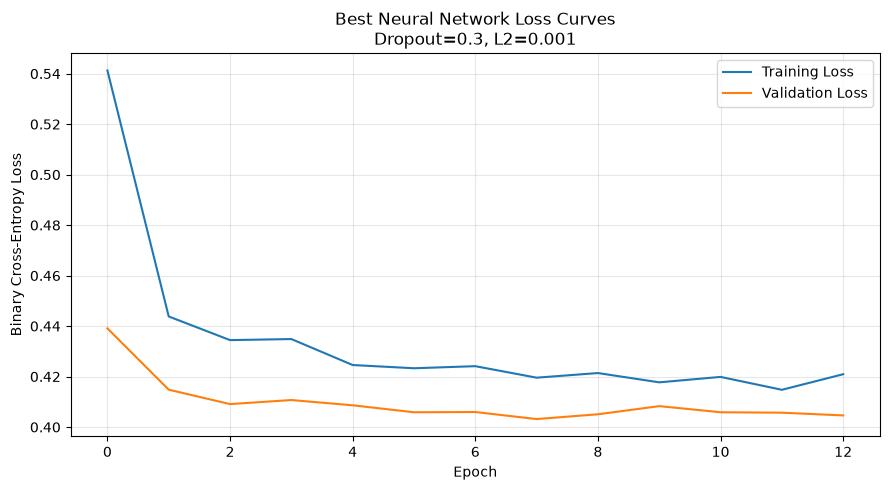

In [20]:

plt.figure(figsize=(9, 5))

plt.plot(
    best_history["train_loss"],
    label="Training Loss"
)

plt.plot(
    best_history["val_loss"],
    label="Validation Loss"
)

plt.title(
    f"Best Neural Network Loss Curves\n"
    f"Dropout={best_dropout}, L2={best_l2}"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [21]:

# Logistic Regression
logistic_test_predictions = logistic_model.predict(
    X_test_processed
)

# Random Forest
rf_test_predictions = random_forest_model.predict(
    X_test_processed
)

# Best Neural Network
best_model.eval()

with torch.no_grad():

    nn_test_probabilities = best_model(
        X_test_tensor.to(DEVICE)
    ).cpu().numpy().flatten()

nn_test_predictions = (
    nn_test_probabilities >= 0.5
).astype(int)

print("Test evaluation predictions generated successfully.")


Test evaluation predictions generated successfully.


In [22]:

test_results = pd.DataFrame({
    "Logistic Regression": calculate_metrics(
        y_test_np,
        logistic_test_predictions
    ),

    "Random Forest": calculate_metrics(
        y_test_np,
        rf_test_predictions
    ),

    "Neural Network": calculate_metrics(
        y_test_np,
        nn_test_predictions
    )
}).T

display(test_results.round(4))


,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.7878,0.6176,0.5267,0.5685
Random Forest,0.7779,0.6055,0.4679,0.5279
Neural Network,0.7835,0.5994,0.5561,0.5770


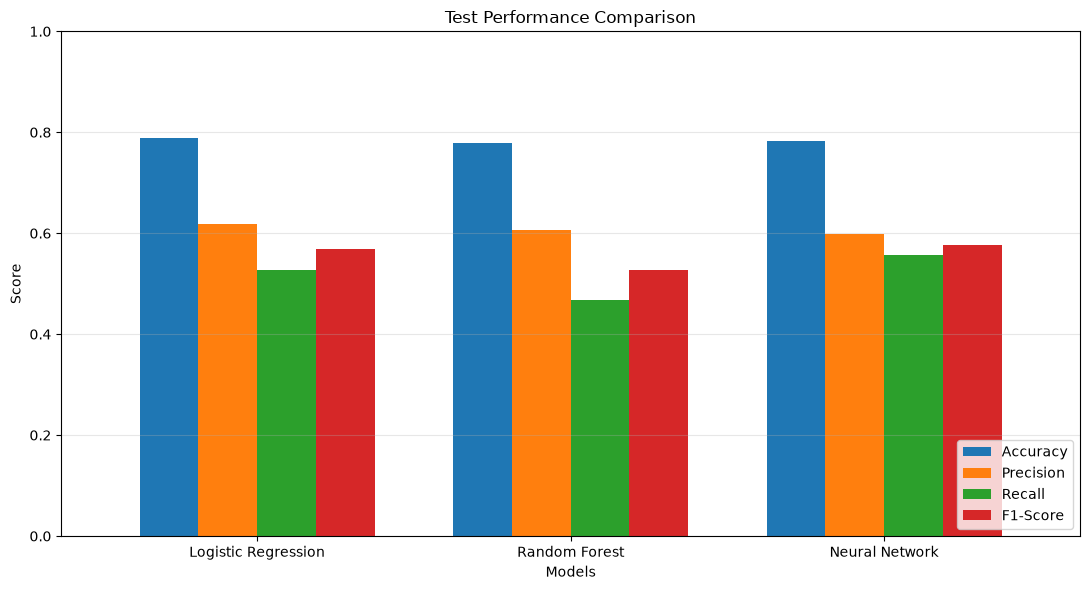

In [23]:

metrics_to_plot = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

test_results[metrics_to_plot].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1),
    width=0.75
)

plt.title("Test Performance Comparison")
plt.xlabel("Models")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


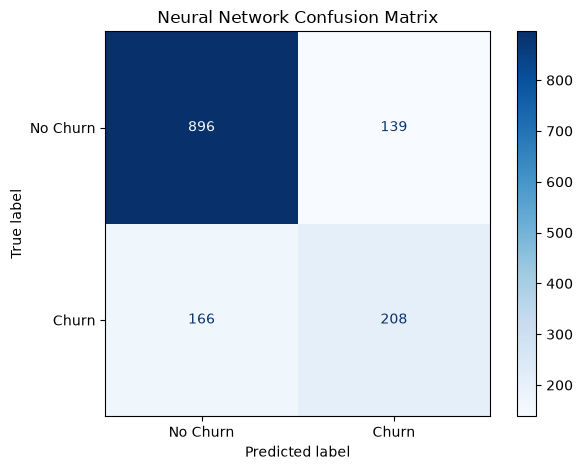

Neural Network Classification Report
              precision    recall  f1-score   support

    No Churn       0.84      0.87      0.85      1035
       Churn       0.60      0.56      0.58       374

    accuracy                           0.78      1409
   macro avg       0.72      0.71      0.72      1409
weighted avg       0.78      0.78      0.78      1409



In [24]:

cm = confusion_matrix(
    y_test_np,
    nn_test_predictions
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
).plot(cmap="Blues")

plt.title("Neural Network Confusion Matrix")
plt.tight_layout()
plt.show()

print("Neural Network Classification Report")

print(
    classification_report(
        y_test_np,
        nn_test_predictions,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)


In [25]:

production_model = test_results["F1-Score"].idxmax()

print("Production Model Recommendation")
print("-" * 45)

print("Recommended Model:", production_model)

print(
    "Test Accuracy:",
    round(test_results.loc[production_model, "Accuracy"], 4)
)

print(
    "Test Precision:",
    round(test_results.loc[production_model, "Precision"], 4)
)

print(
    "Test Recall:",
    round(test_results.loc[production_model, "Recall"], 4)
)

print(
    "Test F1-Score:",
    round(test_results.loc[production_model, "F1-Score"], 4)
)


Production Model Recommendation
---------------------------------------------
Recommended Model: Neural Network
Test Accuracy: 0.7835
Test Precision: 0.5994
Test Recall: 0.5561
Test F1-Score: 0.577


In [26]:

customer_predictions = pd.DataFrame({
    "CustomerID": customer_ids.loc[X_test.index].values,
    "Actual Churn": y_test_np.astype(int),
    "Predicted Churn Probability": nn_test_probabilities,
    "Predicted Churn": nn_test_predictions
})

customer_predictions = customer_predictions.sort_values(
    by="Predicted Churn Probability",
    ascending=False
).reset_index(drop=True)

print("Top 10 Customers with Highest Churn Probability")

display(
    customer_predictions.head(10).style.format({
        "Predicted Churn Probability": "{:.2%}"
    })
)


Top 10 Customers with Highest Churn Probability


,CustomerID,Actual Churn,Predicted Churn Probability,Predicted Churn
0,9300-AGZNL,1,81.43%,1
1,2545-EBUPK,0,80.73%,1
2,4750-ZRXIU,1,80.12%,1
3,1273-MTETI,1,80.04%,1
4,2865-TCHJW,1,78.98%,1
5,1400-MMYXY,1,78.88%,1
6,8884-ADFVN,1,78.75%,1
7,7851-WZEKY,1,78.53%,1
8,0196-VULGZ,1,78.28%,1
9,9057-SIHCH,1,78.24%,1


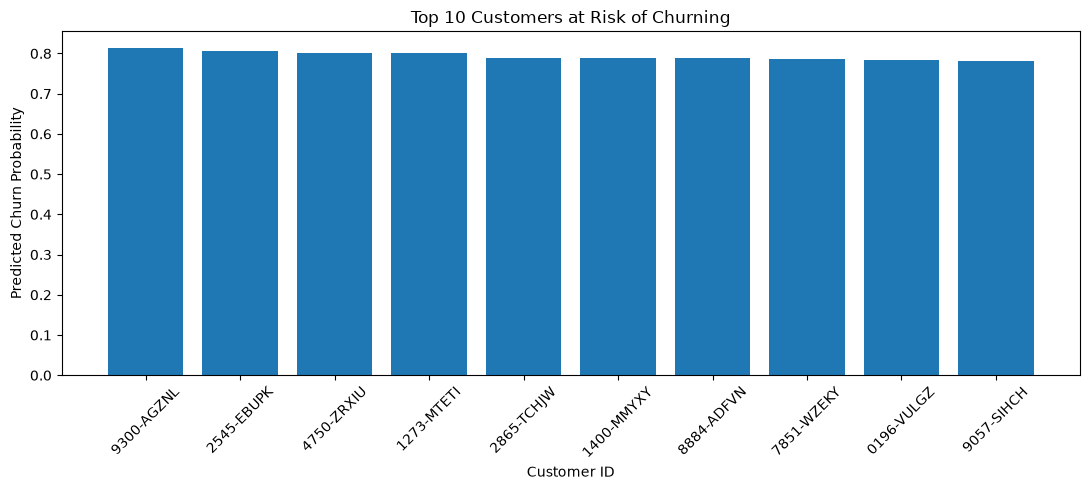

In [27]:

top_customers = customer_predictions.head(10).copy()

plt.figure(figsize=(11, 5))

plt.bar(
    top_customers["CustomerID"].astype(str),
    top_customers["Predicted Churn Probability"]
)

plt.title("Top 10 Customers at Risk of Churning")
plt.xlabel("Customer ID")
plt.ylabel("Predicted Churn Probability")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [28]:

feature_names = preprocessor.get_feature_names_out()

print("Total transformed features:", len(feature_names))

print("Sample feature names:")
print(feature_names[:20])


Total transformed features: 45
Sample feature names:
['numerical__SeniorCitizen' 'numerical__tenure'
 'numerical__MonthlyCharges' 'numerical__TotalCharges'
 'categorical__gender_Female' 'categorical__gender_Male'
 'categorical__Partner_No' 'categorical__Partner_Yes'
 'categorical__Dependents_No' 'categorical__Dependents_Yes'
 'categorical__PhoneService_No' 'categorical__PhoneService_Yes'
 'categorical__MultipleLines_No'
 'categorical__MultipleLines_No phone service'
 'categorical__MultipleLines_Yes' 'categorical__InternetService_DSL'
 'categorical__InternetService_Fiber optic'
 'categorical__InternetService_No' 'categorical__OnlineSecurity_No'
 'categorical__OnlineSecurity_No internet service']


In [29]:

rf_permutation = permutation_importance(
    random_forest_model,
    X_test_processed,
    y_test_np.astype(int),
    scoring="f1",
    n_repeats=5,
    random_state=SEED,
    n_jobs=-1
)

rf_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_permutation.importances_mean,
    "Std": rf_permutation.importances_std
})

rf_importance = rf_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 15 Random Forest Important Features")

display(rf_importance.head(15).round(4))


Top 15 Random Forest Important Features


,Feature,Importance,Std
0,numerical__tenure,0.0957,0.0140
1,categorical__Contract_Month-to-month,0.0767,0.0006
2,numerical__TotalCharges,0.0537,0.0093
3,categorical__InternetService_Fiber optic,0.0345,0.0087
4,categorical__Contract_Two year,0.0221,0.0094
5,numerical__MonthlyCharges,0.0203,0.0120
6,categorical__OnlineSecurity_No,0.0179,0.0081
7,categorical__gender_Male,0.0123,0.0056
8,categorical__TechSupport_No,0.0103,0.0075
9,categorical__Dependents_Yes,0.0092,0.0053


In [30]:

def nn_predict_for_importance(X_array):

    best_model.eval()

    X_tensor = torch.tensor(
        X_array,
        dtype=torch.float32,
        device=DEVICE
    )

    with torch.no_grad():

        probabilities = best_model(
            X_tensor
        ).cpu().numpy().flatten()

    return (probabilities >= 0.5).astype(int)


baseline_nn_f1 = f1_score(
    y_test_np,
    nn_predict_for_importance(X_test_processed),
    zero_division=0
)

nn_importance_values = []

for feature_index, feature_name in enumerate(feature_names):

    importance_scores = []

    for repeat in range(5):

        shuffled_data = X_test_processed.copy()

        np.random.seed(SEED + repeat)

        shuffled_data[:, feature_index] = np.random.permutation(
            shuffled_data[:, feature_index]
        )

        shuffled_predictions = nn_predict_for_importance(
            shuffled_data
        )

        shuffled_f1 = f1_score(
            y_test_np,
            shuffled_predictions,
            zero_division=0
        )

        importance_scores.append(
            baseline_nn_f1 - shuffled_f1
        )

    nn_importance_values.append({
        "Feature": feature_name,
        "Importance": np.mean(importance_scores),
        "Std": np.std(importance_scores)
    })


nn_importance = pd.DataFrame(
    nn_importance_values
).sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 15 Neural Network Important Features")

display(nn_importance.head(15).round(4))


Top 15 Neural Network Important Features


,Feature,Importance,Std
0,numerical__tenure,0.1123,0.0225
1,categorical__Contract_Two year,0.0353,0.0071
2,categorical__Contract_Month-to-month,0.0320,0.0096
3,numerical__TotalCharges,0.0236,0.0141
4,numerical__MonthlyCharges,0.0180,0.0079
5,categorical__InternetService_Fiber optic,0.0161,0.0058
6,categorical__OnlineSecurity_No,0.0153,0.0025
7,categorical__OnlineSecurity_Yes,0.0144,0.0119
8,categorical__TechSupport_No,0.0111,0.0034
9,categorical__PaymentMethod_Electronic check,0.0090,0.0055


,Random Forest,Neural Network
Feature,,
numerical__tenure,0.0957,0.1123
categorical__Contract_Month-to-month,0.0767,0.0320
numerical__TotalCharges,0.0537,0.0236
categorical__InternetService_Fiber optic,0.0345,0.0161
categorical__Contract_Two year,0.0221,0.0353
numerical__MonthlyCharges,0.0203,0.0180
categorical__OnlineSecurity_No,0.0179,0.0153
categorical__gender_Male,0.0123,0.0000
categorical__TechSupport_No,0.0103,0.0111


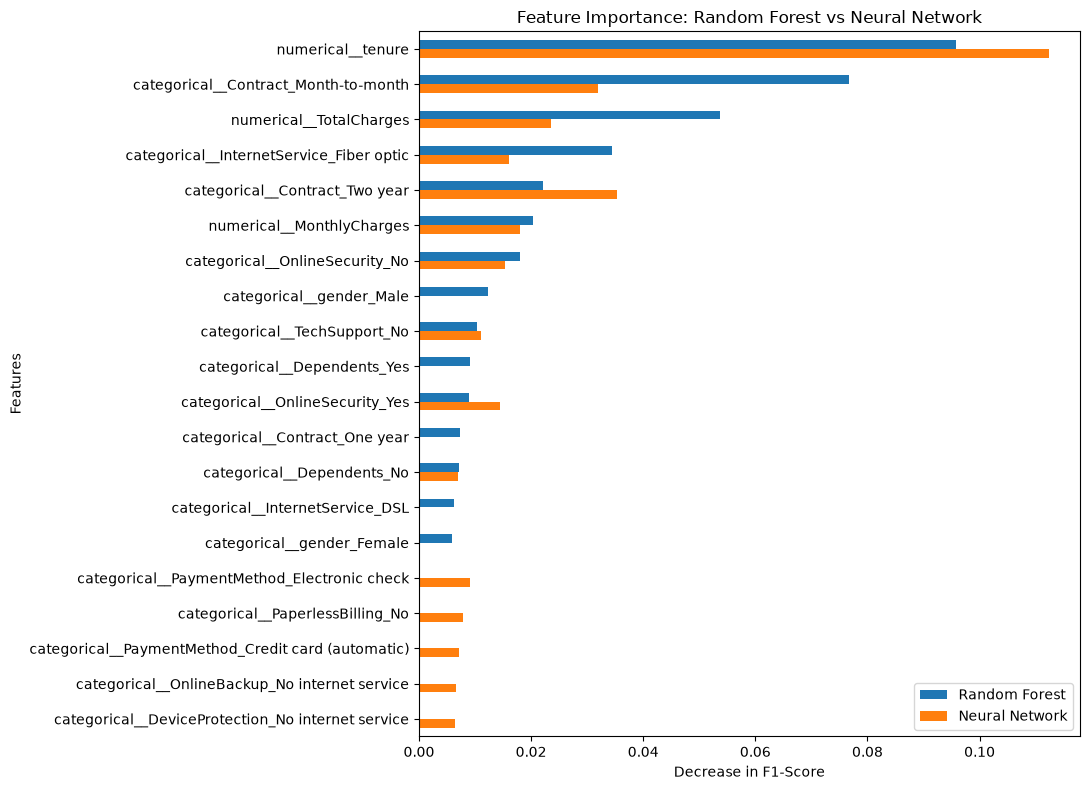

In [31]:

top_n = 15

rf_top = rf_importance.head(top_n).set_index("Feature")
nn_top = nn_importance.head(top_n).set_index("Feature")

importance_comparison = pd.concat(
    [
        rf_top["Importance"].rename("Random Forest"),
        nn_top["Importance"].rename("Neural Network")
    ],
    axis=1
).fillna(0)

importance_comparison = importance_comparison.sort_values(
    by="Random Forest",
    ascending=False
)

display(importance_comparison.round(4))

importance_comparison.plot(
    kind="barh",
    figsize=(11, 8)
)

plt.title("Feature Importance: Random Forest vs Neural Network")
plt.xlabel("Decrease in F1-Score")
plt.ylabel("Features")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [32]:

rf_top_features = set(
    rf_importance.head(10)["Feature"]
)

nn_top_features = set(
    nn_importance.head(10)["Feature"]
)

common_features = rf_top_features.intersection(
    nn_top_features
)

print("Top 10 Random Forest Features:")
print(rf_importance.head(10)["Feature"].tolist())

print("\nTop 10 Neural Network Features:")
print(nn_importance.head(10)["Feature"].tolist())

print("\nCommon Important Features:")
print(sorted(common_features))


Top 10 Random Forest Features:
['numerical__tenure', 'categorical__Contract_Month-to-month', 'numerical__TotalCharges', 'categorical__InternetService_Fiber optic', 'categorical__Contract_Two year', 'numerical__MonthlyCharges', 'categorical__OnlineSecurity_No', 'categorical__gender_Male', 'categorical__TechSupport_No', 'categorical__Dependents_Yes']

Top 10 Neural Network Features:
['numerical__tenure', 'categorical__Contract_Two year', 'categorical__Contract_Month-to-month', 'numerical__TotalCharges', 'numerical__MonthlyCharges', 'categorical__InternetService_Fiber optic', 'categorical__OnlineSecurity_No', 'categorical__OnlineSecurity_Yes', 'categorical__TechSupport_No', 'categorical__PaymentMethod_Electronic check']

Common Important Features:
['categorical__Contract_Month-to-month', 'categorical__Contract_Two year', 'categorical__InternetService_Fiber optic', 'categorical__OnlineSecurity_No', 'categorical__TechSupport_No', 'numerical__MonthlyCharges', 'numerical__TotalCharges', 'nume

In [33]:

business_recommendations = [
    {
        "Recommendation": "Improve Customer Service",
        "Action": "Monitor customer complaints and service issues. "
                  "Provide faster technical support and proactive assistance."
    },
    {
        "Recommendation": "Offer Personalized Retention Plans",
        "Action": "Provide suitable discounts, loyalty benefits, "
                  "and contract upgrades to high-risk customers."
    },
    {
        "Recommendation": "Improve Pricing and Contract Flexibility",
        "Action": "Review expensive monthly plans and encourage "
                  "customers to choose affordable long-term contracts."
    }
]

for index, item in enumerate(business_recommendations, start=1):

    print(f"\nRecommendation {index}: {item['Recommendation']}")
    print("Action:", item["Action"])



Recommendation 1: Improve Customer Service
Action: Monitor customer complaints and service issues. Provide faster technical support and proactive assistance.

Recommendation 2: Offer Personalized Retention Plans
Action: Provide suitable discounts, loyalty benefits, and contract upgrades to high-risk customers.

Recommendation 3: Improve Pricing and Contract Flexibility
Action: Review expensive monthly plans and encourage customers to choose affordable long-term contracts.


In [34]:

discussion = {
    "Logistic Regression": [
        "Suitable for simple classification problems.",
        "Easy to interpret and explain.",
        "Requires less computational power.",
        "Useful when relationships are approximately linear."
    ],

    "Random Forest": [
        "Handles nonlinear relationships.",
        "Works well with tabular datasets.",
        "Provides feature importance.",
        "Requires less neural network tuning."
    ],

    "Neural Networks": [
        "Can learn complex nonlinear relationships.",
        "Useful for large and complex datasets.",
        "Requires more computational resources.",
        "Needs careful regularization to prevent overfitting."
    ]
}

for model_name, points in discussion.items():

    print(f"\n{model_name}")
    print("-" * 40)

    for point in points:
        print("•", point)



Logistic Regression
----------------------------------------
• Suitable for simple classification problems.
• Easy to interpret and explain.
• Requires less computational power.
• Useful when relationships are approximately linear.

Random Forest
----------------------------------------
• Handles nonlinear relationships.
• Works well with tabular datasets.
• Provides feature importance.
• Requires less neural network tuning.

Neural Networks
----------------------------------------
• Can learn complex nonlinear relationships.
• Useful for large and complex datasets.
• Requires more computational resources.
• Needs careful regularization to prevent overfitting.


In [35]:

print("=" * 60)
print("CUSTOMER CHURN PREDICTION - FINAL SUMMARY")
print("=" * 60)

print("\nDataset Information")
print("Total Customers:", len(df))
print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Testing Samples:", len(X_test))

print("\nBest Neural Network Configuration")
print("Architecture: Input -> 64 -> 32 -> 1")
print("Activation: ReLU and Sigmoid")
print("Optimizer: Adam")
print("Loss: Binary Cross-Entropy")
print("Dropout:", best_dropout)
print("L2 Regularization:", best_l2)
print("Early Stopping Patience: 5")

print("\nFinal Test Performance")
display(test_results.round(4))

print("\nRecommended Production Model:", production_model)

print("\nTop Churn Risk Customers")
display(customer_predictions.head(5))

print("=" * 60)


CUSTOMER CHURN PREDICTION - FINAL SUMMARY

Dataset Information
Total Customers: 7043
Training Samples: 4225
Validation Samples: 1409
Testing Samples: 1409

Best Neural Network Configuration
Architecture: Input -> 64 -> 32 -> 1
Activation: ReLU and Sigmoid
Optimizer: Adam
Loss: Binary Cross-Entropy
Dropout: 0.3
L2 Regularization: 0.001
Early Stopping Patience: 5

Final Test Performance


,Accuracy,Precision,Recall,F1-Score
Logistic Regression,0.7878,0.6176,0.5267,0.5685
Random Forest,0.7779,0.6055,0.4679,0.5279
Neural Network,0.7835,0.5994,0.5561,0.5770



Recommended Production Model: Neural Network

Top Churn Risk Customers


,CustomerID,Actual Churn,Predicted Churn Probability,Predicted Churn
0,9300-AGZNL,1,0.814330,1
1,2545-EBUPK,0,0.807258,1
2,4750-ZRXIU,1,0.801153,1
3,1273-MTETI,1,0.800433,1
4,2865-TCHJW,1,0.789849,1
